# Cloud workload forecasting: analysis walkthrough

This notebook follows the analysis behind `reports/final_report.md`. It uses the project's own code in `src/cwfc`.

Rule used throughout: the final 24 timestamps (the holdout) are set aside before any analysis or modelling, and are only scored once at the end. Only the raw-data checks in section 1 look at the full file, and they check structure, not values we model.

In [11]:
from pathlib import Path

import numpy as np
import pandas as pd

from cwfc.capacity import QUANTILES, headroom_margin, validation_errors
from cwfc.models import CANDIDATES, ar_forecast, persistence
from cwfc.predict import COUNT, CPU, HORIZON, build_targets, rolling_origins, select_model

pd.set_option("display.width", 150)
DATA = Path("../challenge_data") if Path("../challenge_data").exists() else Path("challenge_data")

## 1. Raw data checks
Cadence, coverage, missing values, duplicates and value ranges.

In [12]:
cpu = pd.read_csv(DATA / "vm_cpu_readings.csv.gz")
meta = pd.read_csv(DATA / "vm_metadata.csv.gz")

print("rows, columns:", cpu.shape)
print("VMs:", cpu["vm_id"].nunique(), "| timestamps:", cpu["timestamp"].nunique())
print("missing values:", int(cpu.isna().sum().sum()))
print("duplicate (vm_id, timestamp) pairs:", int(cpu.duplicated(["vm_id", "timestamp"]).sum()))
print("gaps between timestamps (s):", cpu["timestamp"].drop_duplicates().sort_values().diff().dropna().unique())
print("VMs per timestamp (min, max):", cpu.groupby("timestamp")["vm_id"].nunique().agg(["min", "max"]).tolist())
cpu[["min_cpu", "max_cpu", "avg_cpu"]].describe()

rows, columns: (1340000, 5)
VMs: 10000 | timestamps: 134
missing values: 0
duplicate (vm_id, timestamp) pairs: 0
gaps between timestamps (s): [300.]
VMs per timestamp (min, max): [10000, 10000]


,min_cpu,max_cpu,avg_cpu
count,1.340000e+06,1.340000e+06,1.340000e+06
mean,6.156478e+00,1.834830e+01,9.388101e+00
std,1.175525e+01,2.161651e+01,1.426601e+01
min,0.000000e+00,1.810795e-02,7.158922e-03
25%,1.487979e+00,4.417642e+00,2.477060e+00
50%,3.227996e+00,9.124204e+00,5.105133e+00
75%,5.331087e+00,2.362418e+01,9.616715e+00
max,9.928158e+01,9.970286e+01,9.948803e+01


The data is regular and clean: one reading every 300 s, the same 10,000 VMs at every timestamp, nothing missing, nothing duplicated, and all values between 0 and 100. So `active_vm_count` will be constant.

## 2. Targets and split
Both target series are built from the full file first, then the last 24 points are held out.

In [13]:
targets = build_targets(DATA)
train = targets.iloc[:-HORIZON]
holdout = targets.iloc[-HORIZON:]
series = train[CPU]
train_end = train.index[-1]

print(len(train), "training steps,", len(holdout), "holdout steps (not used until section 5)")
print("active_vm_count in training (min, max):", train[COUNT].min(), train[COUNT].max())
train.head()

110 training steps, 24 holdout steps (not used until section 5)
active_vm_count in training (min, max): 10000 10000


,active_vm_count,aggregate_cpu_utilization
timestamp,,
0,10000,9.396898
300,10000,9.353775
600,10000,9.454383
900,10000,9.224419
1200,10000,9.143503


## 3. Workload analysis (training window only)

mean 9.414, std 0.194
peak 9.912 at 16500, low 9.112 at 32400, 90% line 9.668


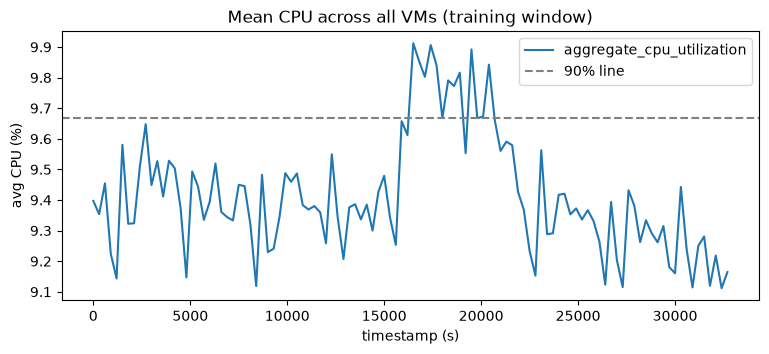

In [14]:
ax = series.plot(figsize=(9, 3.5), title="Mean CPU across all VMs (training window)")
ax.axhline(series.quantile(0.9), color="grey", linestyle="--", label="90% line")
ax.set_xlabel("timestamp (s)")
ax.set_ylabel("avg CPU (%)")
ax.legend()
print(f"mean {series.mean():.3f}, std {series.std():.3f}")
print(f"peak {series.max():.3f} at {series.idxmax()}, low {series.min():.3f} at {series.idxmin()}, 90% line {series.quantile(0.9):.3f}")

The aggregate is calm (std about 0.2 around a mean of 9.4%), with one slow rise above the 90% line in the middle of the window. With only about 9 hours of training data, no daily pattern can be estimated.

0.50     5.50
0.90    19.74
0.95    33.63
0.99    79.62
share of VMs under 5% CPU: 0.464


<Axes: title={'center': 'Mean CPU per VM (log count)'}, ylabel='Frequency'>

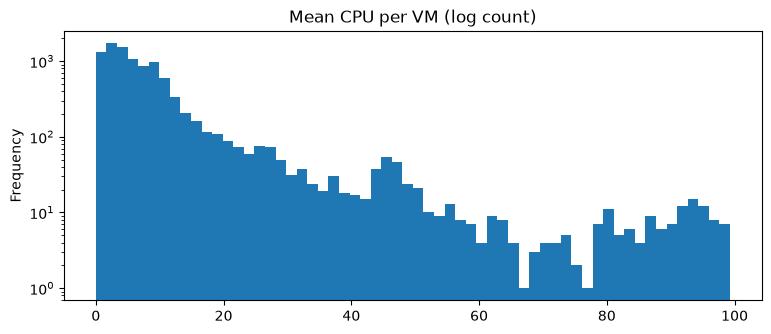

In [15]:
vm_avg = cpu[cpu["timestamp"] <= train_end].groupby("vm_id")["avg_cpu"].mean().rename("vm_mean_cpu")
print(vm_avg.quantile([0.5, 0.9, 0.95, 0.99]).round(2).to_string())
print("share of VMs under 5% CPU:", round((vm_avg < 5).mean(), 3))
vm_avg.plot.hist(bins=60, logy=True, figsize=(9, 3.5), title="Mean CPU per VM (log count)")

Behind the calm total is a very uneven population: almost half of the VMs are close to idle, and a thin tail carries much of the load. Capacity is driven by the heavy VMs, and the idle group is a saving opportunity.

In [ ]:
joined = meta.set_index("vm_id").join(vm_avg)
display(joined.groupby("vm_category")["vm_mean_cpu"].agg(["count", "mean", "median", "max"]).round(2))
print(meta["virtual_core_bucket"].value_counts().to_string())
print("created:", meta["timestamp_vm_created"].unique(),
      "| earliest deletion:", meta["timestamp_vm_deleted"].min(),
      "| training window ends:", train_end)
ax = joined.groupby("vm_category")["vm_mean_cpu"].agg(["median", "mean"]).plot.bar(
    figsize=(6, 3.5), title="Mean CPU per VM by category", ylabel="avg CPU (%)")

,count,mean,median,max
vm_category,,,,
Delay-insensitive,6180,8.26,5.63,99.27
Interactive,3091,11.51,5.58,98.62
Unknown,729,10.35,3.88,97.02


virtual_core_bucket
2      7534
4      1908
8       486
24       62
>24      10
created: [0] | earliest deletion: 40500 | training window ends: 32700


Medians are similar across categories, but Interactive has the highest mean because it contains more heavy VMs. Every VM was created before the trace began and none is deleted inside the window, so there is no churn. That comes from how the release was built, not from the real cloud.

## 4. Validation: baselines and candidate models
Rolling-origin evaluation inside the training window: five starting points, each forecasting the next 24 steps. The holdout is not involved.

In [17]:
origins = rolling_origins(len(train))
rows = []
for name, (func, kwargs) in CANDIDATES.items():
    for o in origins:
        pred = func(series.iloc[:o], HORIZON, **kwargs)
        actual = series.iloc[o:o + HORIZON].to_numpy()
        rows.append({"model": name, "origin": o, "mae": np.abs(actual - pred).mean()})

scores = pd.DataFrame(rows).pivot(index="origin", columns="model", values="mae")
display(scores.round(3))
print(scores.mean().round(4).sort_values().to_string())
print("selected:", select_model(series)[0])

model,ar1,ar2,ar3,persistence
origin,,,,
62,0.268,0.307,0.332,0.297
68,0.269,0.325,0.377,0.301
74,0.114,0.174,0.205,0.124
80,0.087,0.087,0.081,0.087
86,0.127,0.124,0.120,0.132


model
ar1            0.1731
persistence    0.1886
ar2            0.2035
ar3            0.2229
selected: ar1


bias (actual - forecast)  AR(1): -0.142  persistence: -0.159
relative MAE (AR(1) / persistence): 0.918


<Axes: title={'center': 'AR(1) validation MAE by steps ahead'}, xlabel='step'>

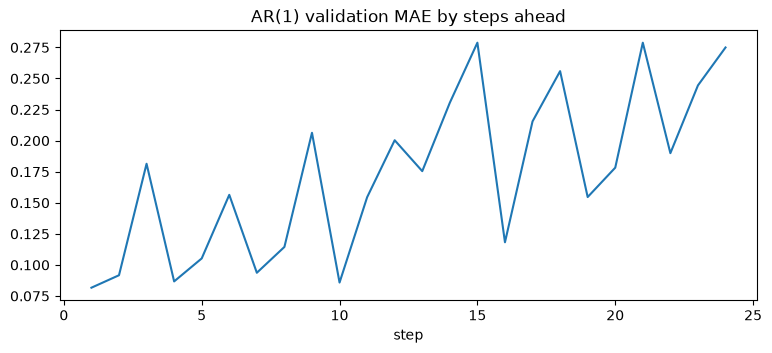

In [18]:
def collect(func, **kwargs):
    frames = []
    for o in origins:
        pred = func(series.iloc[:o], HORIZON, **kwargs)
        actual = series.iloc[o:o + HORIZON].to_numpy()
        frames.append(pd.DataFrame({"step": np.arange(1, HORIZON + 1), "error": actual - pred}))
    return pd.concat(frames)


ar1 = collect(ar_forecast, p=1)
base = collect(persistence)

print(f"bias (actual - forecast)  AR(1): {ar1['error'].mean():.3f}  persistence: {base['error'].mean():.3f}")
print(f"relative MAE (AR(1) / persistence): {ar1['error'].abs().mean() / base['error'].abs().mean():.3f}")
ar1["error"].abs().groupby(ar1["step"]).mean().plot(
    figsize=(9, 3.5), title="AR(1) validation MAE by steps ahead")

AR(1) has the lowest validation error; larger AR orders get worse. Error grows with the forecast horizon, and both models over-forecast slightly in validation.

## 5. Final forecast on the holdout (scored once)

ar1          MAE 0.1290  RMSE 0.1664  bias +0.083
persistence  MAE 0.1468  RMSE 0.1848  bias +0.104


<Axes: title={'center': 'Holdout: actual vs forecast'}, xlabel='timestamp'>

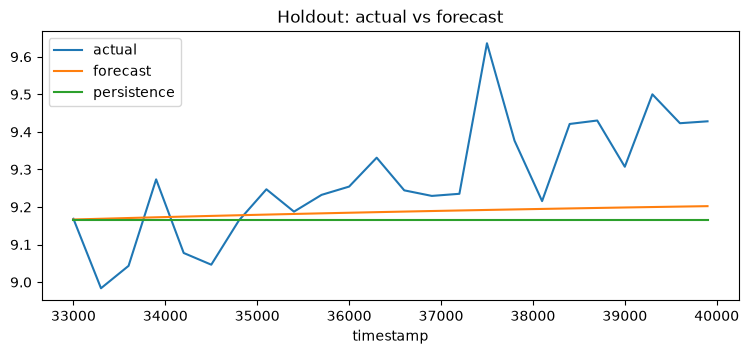

In [19]:
name, _ = select_model(series)
func, kwargs = CANDIDATES[name]
final = np.clip(func(series, HORIZON, **kwargs), 0, 100)
naive = persistence(series, HORIZON)
y = holdout[CPU].to_numpy()

for label, pred in [(name, final), ("persistence", naive)]:
    err = y - pred
    print(f"{label:12s} MAE {np.abs(err).mean():.4f}  RMSE {np.sqrt((err ** 2).mean()):.4f}  bias {err.mean():+.3f}")

pd.DataFrame({"actual": y, "forecast": final, "persistence": naive}, index=holdout.index).plot(
    figsize=(9, 3.5), title="Holdout: actual vs forecast")

The model beats the baseline on the holdout, but the holdout window is calm and the real level drifts up in the last hour while the forecast stays almost flat. Treat the validation gain (about 8%) as the safer estimate.

## 6. Capacity headroom
Margin = quantile of past under-forecast errors from the validation rounds; plan = forecast + margin.

In [20]:
errors = validation_errors(series, func, kwargs)
table = []
for q in QUANTILES:
    margin = headroom_margin(errors, q)
    table.append({
        "quantile": q,
        "margin": round(margin, 3),
        "holdout steps covered": round(float((y <= final + margin).mean()), 2),
        "extra capacity %": round(float((margin / final).mean() * 100), 2),
    })
pd.DataFrame(table)

,quantile,margin,holdout steps covered,extra capacity %
0,0.50,0.000,0.21,0.00
1,0.80,0.000,0.21,0.00
2,0.90,0.072,0.58,0.78
3,0.95,0.113,0.67,1.23
4,0.99,0.149,0.71,1.63


A larger quantile gives fewer shortages at a higher reserved capacity. The 0.99 setting costs about 1.6% extra capacity but still covers only about 71% of the holdout steps, so it is a cheap buffer, not a guarantee. See section 8 of the report.